# code_085 · Support vector machines and margins

**Book:** section 17.4. A self-contained similarity-and-margin laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_17_GUIDE.md), [run evidence](../CHAPTER_17_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_085).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Splits, fitted transformations, model selection and assessment declare their evidence boundaries locally. Synthetic cohort sizes and prevalences are constructed rather than population estimates. All numerical data are generated. These comparisons expose structural assumptions, information boundaries and transformation contracts without field-validity, causal or universal physical-model claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
import threadpoolctl
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=1785;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
CPU: Darwin arm64 seed: 1785


<a id="margins"></a>
## A margin is a decision score

Generate latent points uniform[-1,1]^2, positive inside radius-squared .12, with independent .01 label flips. Stored descriptors are[1000*x1,x2]. Training500/development200/calibration200/final400 roles stay separate. Training-only StandardScaler precedes linear SVC C[.1,1,10] or RBF SVC C[.1,1,10] × gamma[.1,1,3], all with balanced class penalties and the margin-only SVC default. Development balanced accuracy chooses each family, with first grid candidate breaking ties. A logistic sigmoid with fixed C1 fits each chosen model's scores on calibration only, under natural generated prevalence. It is a finite-data calibration estimate, not a guarantee. No threshold or model is selected on final records. C penalizes slack; it does not specify an exact count of permitted violations.


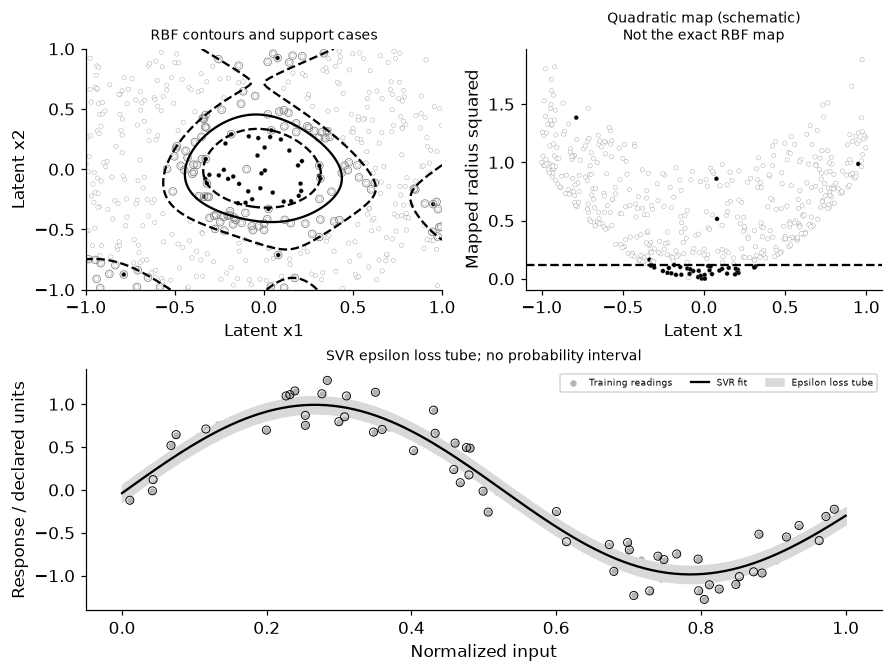

In [2]:
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC,SVR
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score,brier_score_loss,log_loss,mean_squared_error
from scipy.special import expit
def generate(n):
 z=rng.uniform(-1,1,(n,2));y=(np.sum(z*z,axis=1)<.12).astype(int);y^=(rng.random(n)<.01).astype(int);return z*np.array([1000,1]),y
X,y=generate(500);Xd,yd=generate(200);Xc,yc=generate(200);Xt,yt=generate(400);sc=StandardScaler().fit(X);S=sc.transform(X);D=sc.transform(Xd);C=sc.transform(Xc);T=sc.transform(Xt);fits={};rows=[]
for family in ['Linear','RBF']:
 options=[]
 for penalty in [.1,1,10]:
  for gamma in ([.1,1,3] if family=='RBF' else ['scale']):
   model=SVC(C=penalty,kernel='rbf' if family=='RBF' else 'linear',gamma=gamma,class_weight='balanced').fit(S,y);options.append((float(balanced_accuracy_score(yd,model.predict(D))),model,penalty,gamma))
 dev,model,penalty,gamma=max(options,key=lambda a:a[0]);cal=LogisticRegression(C=1).fit(model.decision_function(C)[:,None],yc);p=cal.predict_proba(model.decision_function(T)[:,None])[:,1];margin=(2*y-1)*model.decision_function(S);assert not hasattr(model,'predict_proba');assert set(model.support_).issubset(range(len(y)));assert np.all((p>0)&(p<1))
 row={'family':family,'C':penalty,'gamma':gamma,'development_candidates':len(options),'development_balanced_accuracy':dev,'final_margin_zero_balanced_accuracy':float(balanced_accuracy_score(yt,model.predict(T))),'final_probability_half_balanced_accuracy':float(balanced_accuracy_score(yt,p>=.5)),'final_brier':float(brier_score_loss(yt,p)),'final_log_loss':float(log_loss(yt,p)),'support_vectors':int(model.n_support_.sum()),'training_hinge_violations':int(np.sum(margin<1-1e-6)),'calibration_slope':float(cal.coef_[0,0]),'calibration_intercept':float(cal.intercept_[0])};rows.append(row);fits[family]=(model,cal,p)
RESULTS['families']=rows;RESULTS['roles']={key:{'rows':len(v),'positives':int(v.sum())} for key,v in [('training',y),('development',yd),('calibration',yc),('final',yt)]}
# Independent, fixed-parameter regression fixture; epsilon is a loss tolerance, not coverage.
rx=np.sort(rng.uniform(0,1,100));ry=np.sin(6*rx)+rng.normal(0,.15,100);rxt=rng.uniform(0,1,120);ryt=np.sin(6*rxt)+rng.normal(0,.15,120);svr=SVR(C=5,epsilon=.1,gamma=4).fit(rx[:,None],ry);residual=ry-svr.predict(rx[:,None]);assert np.all(np.abs(residual[np.setdiff1d(np.arange(100),svr.support_)])<=.1+2e-3)
RESULTS['SVR']={'training':100,'final':120,'C':5,'epsilon':.1,'gamma':4,'support_vectors':int(len(svr.support_)),'training_fraction_in_epsilon_tube':float(np.mean(np.abs(residual)<=.1+2e-3)),'final_mse':float(mean_squared_error(ryt,svr.predict(rxt[:,None]))),'interval_claimed':False}
fig=plt.figure(figsize=(8,6));gs=fig.add_gridspec(2,2);a=fig.add_subplot(gs[0,0]);b=fig.add_subplot(gs[0,1]);c=fig.add_subplot(gs[1,:]);model=fits['RBF'][0];xx,yy=np.meshgrid(np.linspace(-1,1,160),np.linspace(-1,1,160));grid=np.column_stack([1000*xx.ravel(),yy.ravel()]);zz=model.decision_function(sc.transform(grid)).reshape(xx.shape);a.contour(xx,yy,zz,levels=[-1,0,1],colors='black',linestyles=['--','-','--']);a.scatter(X[:,0]/1000,X[:,1],c=y,cmap='Greys',vmin=0,vmax=1,s=8,edgecolors='.5',linewidths=.2);a.scatter(X[model.support_,0]/1000,X[model.support_,1],s=25,facecolors='none',edgecolors='.5',linewidths=.5);a.set(xlabel='Latent x1',ylabel='Latent x2',title='RBF contours and support cases')
z=X/np.array([1000,1]);b.scatter(z[:,0],np.sum(z*z,axis=1),c=y,cmap='Greys',s=8,edgecolors='.5',linewidths=.2);b.axhline(.12,color='black',ls='--');b.set(xlabel='Latent x1',ylabel='Mapped radius squared',title='Quadratic map (schematic)\nNot the exact RBF map')
g=np.linspace(0,1,200);pred=svr.predict(g[:,None]);c.scatter(rx,ry,s=10,color='.7',label='Training readings');c.plot(g,pred,color='black',label='SVR fit');c.fill_between(g,pred-.1,pred+.1,color='.85',label='Epsilon loss tube');c.scatter(rx[svr.support_],ry[svr.support_],s=28,facecolors='none',edgecolors='black',linewidths=.6);c.set(xlabel='Normalized input',ylabel='Response / declared units',title='SVR epsilon loss tube; no probability interval');c.legend(fontsize=6,ncol=3);plt.show()


<a id="calibration"></a>
## Calibrated decisions have a separate evidence boundary

Compare raw margin-zero decisions with probability-half decisions after the separately fitted sigmoid. Balanced fitting penalties and balanced-accuracy selection emphasize both classes; they do not establish population probabilities. Final Brier/log loss assess the probability estimates without choosing the mapping again. Five equal-count groups retain eighty final observations each, showing observed positive fraction beside mean fitted probability. Finite group agreement is not a universal calibration guarantee. The displayed quadratic-radius map illustrates how nonlinear boundaries can become simple after a transformation; the RBF model uses its own implicit feature space. The SVR tolerance is specified in response units and is not a predictive confidence level.


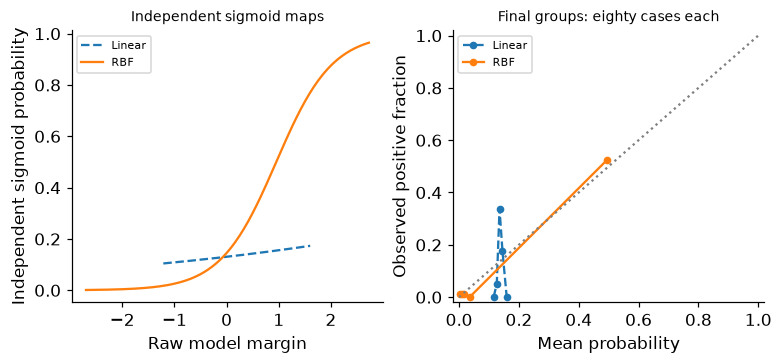

In [3]:
fig,axes=plt.subplots(1,2,figsize=(7,3.2));groups={}
for family,style in [('Linear','--'),('RBF','-')]:
 model,cal,p=fits[family];score=model.decision_function(T);g=np.linspace(score.min(),score.max(),200);axes[0].plot(g,cal.predict_proba(g[:,None])[:,1],style,label=family);order=np.argsort(p);bins=np.array_split(order,5);record=[{'n':len(ix),'mean_probability':float(p[ix].mean()),'positive_fraction':float(yt[ix].mean())} for ix in bins];assert sum(v['n'] for v in record)==len(yt);groups[family]=record;axes[1].plot([v['mean_probability'] for v in record],[v['positive_fraction'] for v in record],style,marker='o',ms=4,label=family)
axes[0].set(xlabel='Raw model margin',ylabel='Independent sigmoid probability',title='Independent sigmoid maps');axes[0].legend(fontsize=7);axes[1].plot([0,1],[0,1],':',color='.5');axes[1].set(xlabel='Mean probability',ylabel='Observed positive fraction',title='Final groups: eighty cases each',xlim=(-.02,1.02),ylim=(-.02,1.02));axes[1].legend(fontsize=7);RESULTS['final_calibration_groups']=groups;plt.show()


In [4]:
summary={'example_id':'code_085','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['soft margins and balanced penalties', 'kernel boundary versus schematic feature map', 'independent score calibration', 'epsilon-insensitive regression'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["soft margins and balanced penalties", "kernel boundary versus schematic feature map", "independent score calibration", "epsilon-insensitive regression"], "elapsed_seconds": 0.438, "example_id": "code_085", "hardware": "Darwin arm64 CPU", "results": {"SVR": {"C": 5, "epsilon": 0.1, "final": 120, "final_mse": 0.019058873595206187, "gamma": 4, "interval_claimed": false, "support_vectors": 57, "training": 100, "training_fraction_in_epsilon_tube": 0.49}, "families": [{"C": 0.1, "calibration_intercept": -1.8962714162964025, "calibration_slope": 0.20761923584548644, "development_balanced_accuracy": 0.62, "development_candidates": 3, "family": "Linear", "final_brier": 0.10056130917333411, "final_log_loss": 0.3540707130552716, "final_margin_zero_balanced_accuracy": 0.6640062597809077, "final_probability_half_balanced_accuracy": 0.5, "gamma": "scale", "support_vectors": 496, "training_hinge_violations": 496}, {"C": 1, "calibration_intercept": -1